## 1. Loading the 4 Nov recordings (CS230, thin PMMA)

This dataset is Ella's second attempt at intra/inter PUF measurements:
- **Intras** – 5 recordings of the *same* region (near the "J" grid mark), ~3 min apart.
  Used to test **reliability**: does the same region give the same fingerprint?
- **Inters** – 3 recordings of *different* regions.
  Used to test **uniqueness**: do different regions give different fingerprints?

Each recording has a `.raw` file (the video) and a `.json` file (the acquisition settings). Rather than typing in frame sizes by hand, I read them from each `.json` so that the loading always maatches how the data was actually recorded (Ella's README warns that settings differ between recordings).

I reuse two functions from the supplied `qd_blinking.py`:
- `load_raw_video()` returns a memory-map, so the 500 MB files are not loaded into RAM all at once - frames are only read from disk wheb they're used.
- `timing()` converts each recording's per-frame timestamps (stored in the `.json`) into a time axis in seconds, and checks the timestamps are consistent. The original paper notebook ran without timestamps, so its results were in frames only.


In [11]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from qd_blinking import load_raw_video, projections, timing

# Folder holding the 4 Nov data
base = Path("/Users/william/Documents/Documents - William’s MacBook Air/UNI/MASTERS PROJECT"
            "/Additional Data/Intra-Inter Attempt 2 04_11_26 (more successful)")

intra_dir = base / "Intras - same region"
inter_dir = base / "inters- different regions"

# sorted() puts them in time order, because the filenames contain the time
intra_paths = sorted(intra_dir.glob("*.raw"))
inter_paths = sorted(inter_dir.glob("*.raw"))

print(f"Found {len(intra_paths)} intra and {len(inter_paths)} inter recordings\n")


def load_recording(raw_path):
    """Load one recording using the settings stored in its .json file.
    Returns the video, its metadata, and a time axis in seconds."""
    meta = json.loads(raw_path.with_suffix(".json").read_text())
    n_frames, height, width = meta["shape"]

    video = load_raw_video(
        raw_path,
        width=width,
        height=height,
        header_bytes=0,
        dtype="<u2",
        expected_frames=n_frames,
    )

    # The camera's own frame interval (the PC timestamps have a few ms of jitter)
    frame_interval_s = meta["timing"]["frame_interval_ms"] / 1000

    # Check no frames were dropped before trusting a regular time axis
    if meta["skipped_frame_count"] != 0:
        raise ValueError(f"{raw_path.name}: {meta['skipped_frame_count']} frames were skipped")

    # Check the PC timestamps agree with the camera interval over the whole recording
    stamps = np.array(meta["timestamps_unix"])
    span_from_stamps = stamps[-1] - stamps[0]
    span_expected = (n_frames - 1) * frame_interval_s
    if abs(span_from_stamps - span_expected) > 0.01 * span_expected:
        raise ValueError(f"{raw_path.name}: timestamps span {span_from_stamps:.2f} s "
                         f"but camera interval implies {span_expected:.2f} s")

    time_s, regular_interval = timing(
        n_frames,
        exposure_s=meta["exposure_ms"] / 1000,
        frame_interval_s=frame_interval_s,
    )
    meta["time_s"] = time_s
    meta["regular_interval_s"] = regular_interval
    meta["timestamp_jitter_ms"] = 1000 * np.std(np.diff(stamps))
    return video, meta

# Load everything into dictionaries, keyed by a short name e.g. "100721"
intras, inters, metas = {}, {}, {}

for p in intra_paths:
    name = p.stem.split("_")[-1]
    intras[name], metas[name] = load_recording(p)

for p in inter_paths:
    name = p.stem.split("_")[-1]
    inters[name], metas[name] = load_recording(p)

# Summary table so I can check every recording matches what I expect
print(f"{'name':>8} {'type':>6} {'frames x H x W':>18} {'exposure (ms)':>14} "
      f"{'duration (s)':>13} {'PC jitter (ms)':>15}")
for name, meta in metas.items():
    kind = "intra" if name in intras else "inter"
    print(f"{name:>8} {kind:>6} {str(tuple(meta['shape'])):>18} "
          f"{meta['exposure_ms']:>14.1f} {meta['time_s'][-1]:>13.1f} "
          f"{meta['timestamp_jitter_ms']:>15.2f}")

Found 5 intra and 3 inter recordings

    name   type     frames x H x W  exposure (ms)  duration (s)  PC jitter (ms)
  100721  intra   (1000, 512, 512)          100.0          99.9            0.93
  101036  intra   (1000, 512, 512)          100.0          99.9            0.89
  101425  intra   (1000, 512, 512)          100.0          99.9            0.81
  101720  intra   (1000, 512, 512)          100.0          99.9            0.87
  101949  intra   (1000, 512, 512)          100.0          99.9            0.83
  095458  inter   (1000, 512, 512)          100.0          99.9            0.91
  102951  inter   (1000, 512, 512)          100.0          99.9            0.94
  105225  inter   (1000, 512, 512)          100.0          99.9            0.84


### What this shows

- All 8 recordings loaded: 5 intras (same region) and 3 inters (different regions).
- Every recording has identical acquisition settings: 1000 frames of 512 × 512 pixels
  at 100 ms exposure, spanning 99.9 s (999 frame intervals). This matches Ella's email
  and means the recordings can be compared directly without any rescaling.
- The PC timestamps jitter by 0.8–0.9 ms (standard deviation) around the 100 ms frame
  interval in every recording. This is roughly 1 % of the interval, so the timestamps
  can't be used as exact capture times, but no frames were dropped and their total span
  agrees with the camera's frame interval. A regular 100 ms time axis is therefore
  justified for all 8 recordings.
- With a known regular interval, later blinking durations can be given in seconds
  rather than frames. The original paper notebook couldn't do this because no timing
  information was supplied to it.
- From the filenames, the 5 intras were taken over ~13 minutes (10:07–10:20), while
  the inters bracket them (09:54, 10:29, 10:52). Any differences between intras
  therefore reflect changes over minutes, not hours or days.
- Exposure here is 100 ms vs 50 ms in the Zenodo and 21 Oct data, so blinking events
  shorter than ~0.1 s will be averaged out. Comparisons between datasets must be made
  in seconds, not frames.

## 2. Time-averaged images

The first step of the paper's pipeline is to average each video over time. This makes
persistent fluorescent features stand out and averages away frame-to-frame noise. For a
PUF, the mean image is the simplest version of the spatial "fingerprint" of a region.

I use the supplied `projections()` function, which returns both:
- the **mean image** – each pixel averaged over all 1000 frames;
- the **maximum image** – each pixel's brightest value in any frame. This picks up
  emitters that are OFF most of the time and so look faint in the mean (Sec. 5.1 of the
  paper). I store it now for use later.

Before any quantitative analysis, I want to check by eye that:
1. the 5 intras look like the **same** region (they should, as the sample wasn't moved);
2. the 3 inters look **different** from the intras and from each other;
3. the images match the previews in Ella's email, as a check that loading worked.


All intras are shown on the **same brightness scale**, so any overall dimming between
repeats (e.g. from bleaching) would be visible rather than hidden by auto-contrast.

Projected 100721
Projected 101036
Projected 101425
Projected 101720
Projected 101949
Projected 095458
Projected 102951
Projected 105225


/var/folders/gb/g78cvbw55qq4tjkh2gzpqh2c0000gn/T/ipykernel_8285/890269557.py:40: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


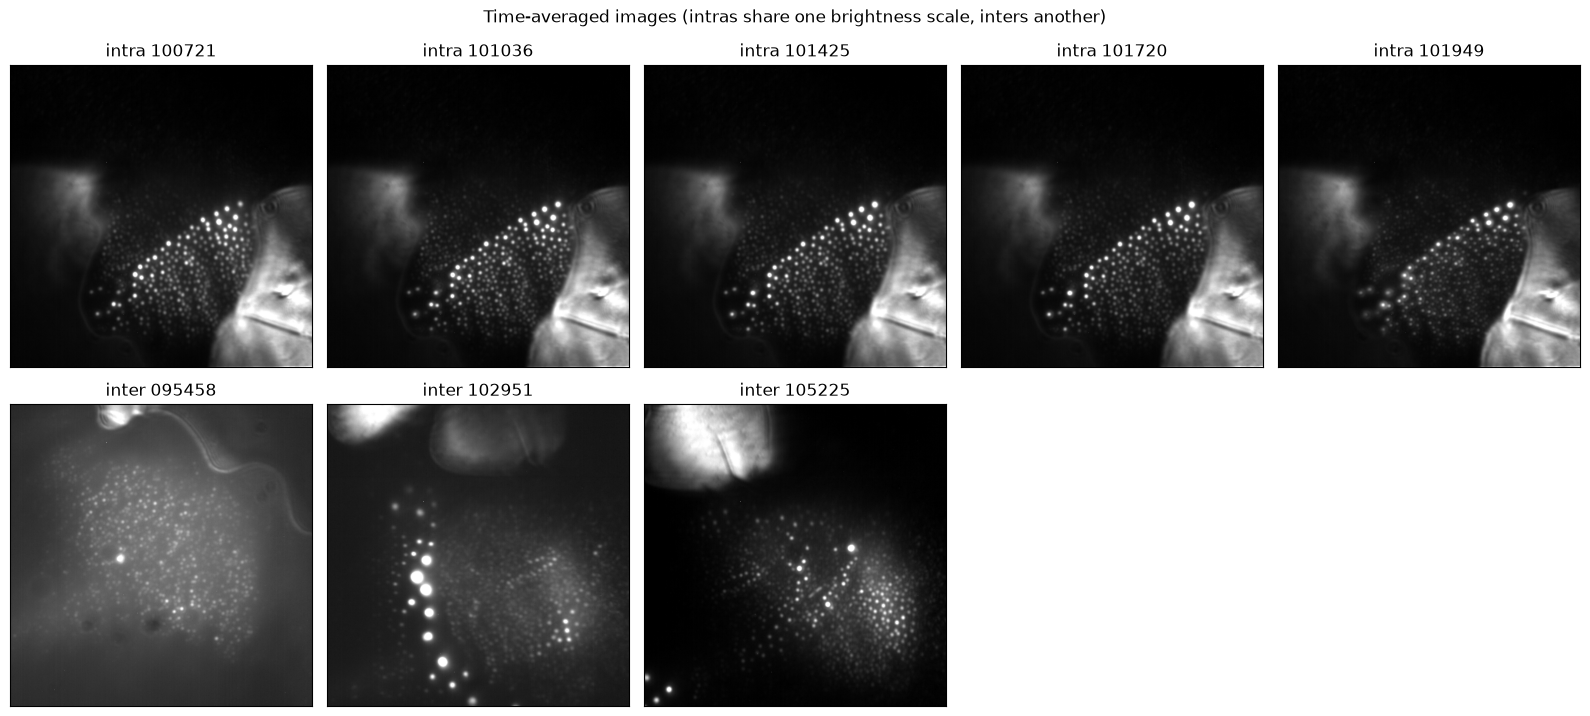


    name   type  median (ADU)  99.9th pct (ADU)
  100721  intra         183.7             878.5
  101036  intra         183.3             898.1
  101425  intra         181.9             859.9
  101720  intra         181.9             844.1
  101949  intra         183.8             808.1
  095458  inter         221.0             509.7
  102951  inter         174.0            1526.2
  105225  inter         135.2             537.7


In [12]:
# Compute mean and max projections for every recording (reads each file once)
mean_imgs, max_imgs = {}, {}

for name, video in {**intras, **inters}.items():
    mean_imgs[name], max_imgs[name] = projections(video)
    print(f"Projected {name}")


def shared_limits(images, low=1, high=99.5):
    """
    Brightness limits shared across a set of images, from percentiles of all their pixels.
    Using percentiles stops a few very bright pixels from washing out the display.
    """
    all_pixels = np.concatenate([img.ravel() for img in images])
    return np.percentile(all_pixels, [low, high])


intra_lims = shared_limits([mean_imgs[n] for n in intras])
inter_lims = shared_limits([mean_imgs[n] for n in inters])

fig, axes = plt.subplots(2, 5, figsize=(16, 7.5), layout ="constrained")

for ax, name in zip(axes[0], intras):
    ax.imshow(mean_imgs[name], cmap="gray", vmin=intra_lims[0], vmax=intra_lims[1])
    ax.set_title(f"intra {name}")

for ax, name in zip(axes[1], inters):
    ax.imshow(mean_imgs[name], cmap="gray", vmin=inter_lims[0], vmax=inter_lims[1])
    ax.set_title(f"inter {name}")

# The inter row only has 3 images; hide the 2 empty panels
for ax in axes[1, len(inters):]:
    ax.set_visible(False)

for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle("Time-averaged images (intras share one brightness scale, inters another)")
plt.tight_layout()
plt.show()

# Simple numbers to back up the visual comparison:
#   median    ~ the background level (most pixels are not on a QD)
#   99.9th %  ~ the brightness of the brightest features
print(f"\n{'name':>8} {'type':>6} {'median (ADU)':>13} {'99.9th pct (ADU)':>17}")
for name, img in mean_imgs.items():
    kind = "intra" if name in intras else "inter"
    print(f"{name:>8} {kind:>6} {np.median(img):>13.1f} {np.percentile(img, 99.9):>17.1f}")

### What this shows

- **The 5 intras show the same region.** The same diagonal band of spots appears in the
  same place in every repeat, matching Ella's email preview. By eye, any shift between
  repeats is at most a few pixels; this will be measured properly when matching spots.
- **The images contain large bright structures that are not QDs**: a hazy patch on the
  left and a bright, sharp-edged feature on the right (likely an air pocket or PMMA edge,
  as Ella's README describes for the thin-PMMA samples). These will need excluding when
  detecting spots, so they aren't mistaken for emitters.
- **The background is stable across the intras** (median 181.9–183.8 ADU, a spread of
  ~1 %), so the overall illumination and camera offset didn't change between repeats.
- **The brightest features dim slightly over the ~13 minutes.** The 99.9th percentile
  falls from 878.5 ADU (first intra) to 808.1 ADU (last), an ~8 % drop, with most of it
  in the final repeat. The last intra (101949) also looks visibly softer, with smeared
  bright spots on the left. This could be bleaching, a small focus change, or sample
  movement; the focus check in step 3 is designed to separate these.
  *Caveat:* the 99.9th percentile may include pixels from the bright non-QD structures,
  so it is only a rough indicator. Per-spot brightness will be measured in later steps.
- **The 3 inters are clearly different** from the intras and from each other:
  - 095458: hazy, high background (median 221 ADU) with a dense field of dim spots and a
    curved boundary across the top;
  - 102951: a vertical line of very large, bright features (99.9th percentile 1526 ADU,
    almost twice the intras) — likely clusters — beside a sparser field of dimmer spots;
  - 105225: dark background (median 135 ADU) with a dense patch of spots and a bright
    structure top-left.
- The background differs by up to ~60 % between regions (135–221 ADU), so different
  parts of the sample have quite different local conditions (PMMA thickness, air
  pockets, grid markings). Comparisons between regions will need to use
  background-corrected values.
- This is still a visual comparison. Next, I check focus stability within each
  recording, then detect and match individual spots.

## 3. Focus and stability check within each recording

In the Zenodo recording I analysed earlier, most spots lost 80–100 % of their measured
intensity, which turned out to be most likely caused by **defocus**: the extraction uses
a fixed 3 px aperture, so if a spot blurs, light spreads outside the aperture and the
measured intensity drops even though the QD hasn't changed. Before trusting any traces
from this dataset, I need to check each recording is stable.

**Method:** split each recording into 10 blocks of 100 frames (10 s each). For each block:
1. make a mean image with the supplied `projections()`;
2. detect and fit spots with the supplied `fit_candidates()`, which fits a 2D Gaussian to
   each spot and returns its width `R` (σ, in pixels) and peak `amplitude`;
3. record the **median R** and **median amplitude** of the retained spots, and **how many**
   spots were retained;
4. measure how far the whole image has **drifted** relative to the first block, using phase cross-correlation (`skimage`)

Using the median across all spots makes the measure robust to a few bad fits (e.g. on the
bright non-QD structures).

**How to read the results:**

| Cause | Median R | Median amplitude | No. of spots | Drift |
|---|---|---|---|---|
| Defocus | rises | falls | falls | ~0 |
| Bleaching | flat | falls | may fall | ~0 |
| Sample movement | flat | flat | flat | rises |
| Stable | flat | flat | flat | ~0 |

For reference, an ideal diffraction-limited spot in this setup has σ ≈ 1.7 px (paper,
Sec. 5.1), so in-focus spots should have R a little above that.


Done 100721
Done 101036
Done 101425
Done 101720
Done 101949
Done 095458
Done 102951
Done 105225


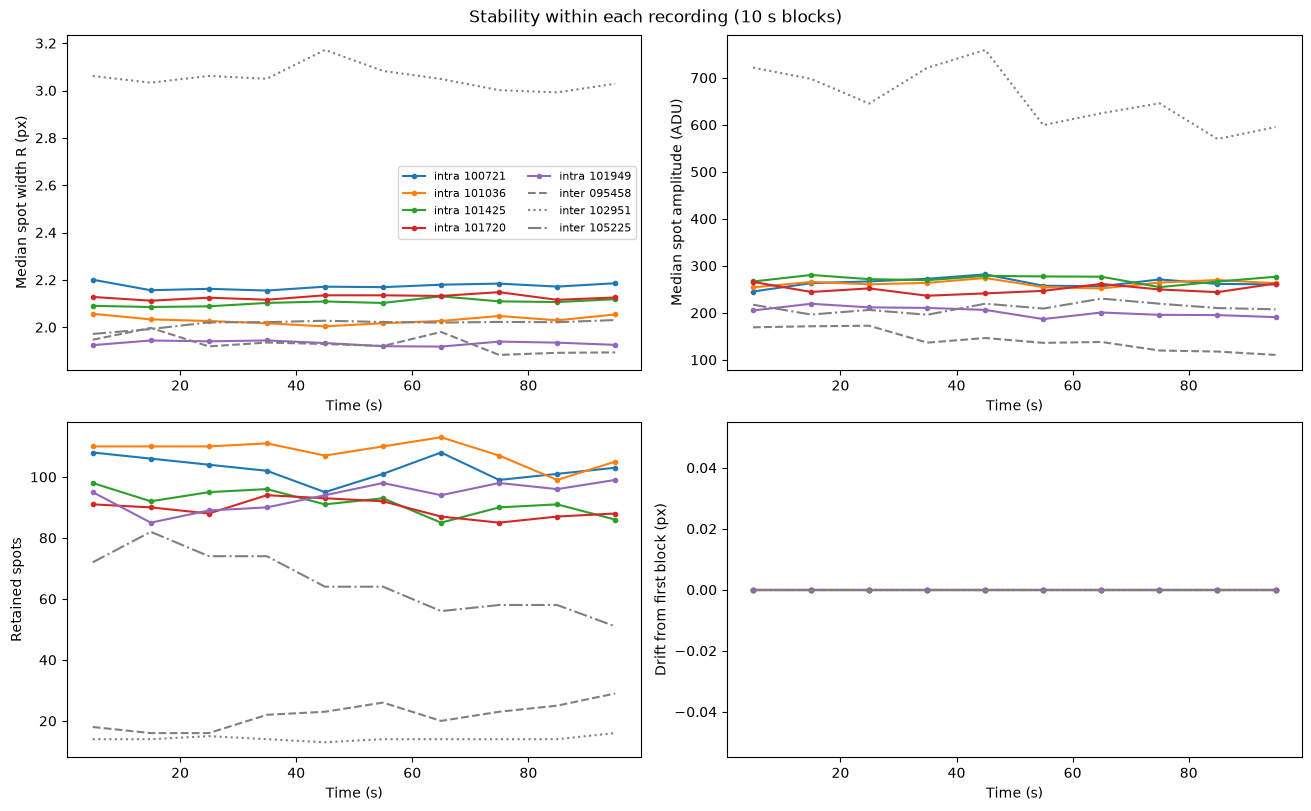

    name   type  R first   R last    ΔR %  amp first  amp last  Δamp % max drift
  100721  intra     2.20     2.19    -0.7      245.3     260.5     6.2      0.00
  101036  intra     2.06     2.05    -0.1      254.1     262.9     3.5      0.00
  101425  intra     2.09     2.12     1.3      266.7     276.7     3.8      0.00
  101720  intra     2.13     2.13    -0.1      265.8     262.3    -1.3      0.00
  101949  intra     1.92     1.93     0.1      205.0     190.8    -6.9      0.00
  095458  inter     1.95     1.89    -2.7      169.2     110.5   -34.7      0.00
  102951  inter     3.06     3.03    -1.1      721.7     595.2   -17.5      0.00
  105225  inter     1.97     2.03     3.0      217.2     207.5    -4.5      0.00


In [21]:
import pandas as pd
from qd_blinking import fit_candidates, AnalysisConfig
from skimage.registration import phase_cross_correlation

cfg = AnalysisConfig()   # the paper's default detection and fitting settings
BLOCK = 100              # frames per block (= 10 s at 100 ms)


def stability_over_time(video, time_s, block=BLOCK):
    """Track spot width, spot brightness and spot count block by block."""
    rows = []
    reference = None

    for start in range(0, len(video), block):
        stop = min(start + block, len(video))
        block_mean, _ = projections(video[start:stop])

        fits = fit_candidates(block_mean, cfg)
        kept = fits[fits["retained"]]

        # Drift of this block relative to the first block, to 0.1 px precision
        if reference is None:
            reference = block_mean
            shift = np.zeros(2)
        else:
            shift, _, _ = phase_cross_correlation(reference, block_mean, upsample_factor=10)
        
        rows.append(dict(
            t=time_s[start:stop].mean(),
            n_spots=len(kept),
            median_R=kept["R"].median(),
            median_amp=kept["amplitude"].median(),
            drift_px = np.hypot(*shift),
        ))
    return pd.DataFrame(rows)


stability = {}
for name, video in {**intras, **inters}.items():
    stability[name] = stability_over_time(video, metas[name]["time_s"])
    print(f"Done {name}")


# ---- Plot each measure against time ----
measures = [("median_R", "Median spot width R (px)"),
            ("median_amp", "Median spot amplitude (ADU)"),
            ("n_spots", "Retained spots"),
            ("drift_px", "Drift from first block (px)")]

fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout="constrained")

for ax, (col, label) in zip(axes.flat, measures):
    for name, df in stability.items():
        if name in intras:
            ax.plot(df["t"], df[col], "-o", ms=3, label=f"intra {name}")
        else:
            style = {"095458": "--", "102951": ":", "105225": "-."}[name]
            ax.plot(df["t"], df[col], style, color="grey", label=f"inter {name}")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel(label)

axes[0,0].legend(fontsize = 8, ncol = 2)
fig.suptitle("Stability within each recording (10 s blocks)")
plt.show()


# ---- Summary: change from first to last block ----
print(f"{'name':>8} {'type':>6} {'R first':>8} {'R last':>8} {'ΔR %':>7} "
      f"{'amp first':>10} {'amp last':>9} {'Δamp %':>7}{'max drift':>10}")
for name, df in stability.items():
    kind = "intra" if name in intras else "inter"
    r0, r1 = df["median_R"].iloc[0], df["median_R"].iloc[-1]
    a0, a1 = df["median_amp"].iloc[0], df["median_amp"].iloc[-1]
    print(f"{name:>8} {kind:>6} {r0:>8.2f} {r1:>8.2f} {100*(r1-r0)/r0:>7.1f} "
          f"{a0:>10.1f} {a1:>9.1f} {100*(a1-a0)/a0:>7.1f}{df['drift_px'].max():>10.2f}")

**Drift (not yet verified).** Phase cross-correlation reported exactly 0.00 px drift in
every block of every recording. This may be an artefact of the camera's fixed-pattern
noise, which stays fixed relative to the camera rather than the sample. Step 3b checks
this independently using spot positions.

### 3b. Drift within each recording

Chunk 3 checks whether spots blur or dim, but not whether the **sample moves**. Movement
matters for two reasons: the fixed 3 px aperture assumes each spot stays in place
during a recording, and recordings will later need aligning with each other (step 5).

My first attempt used phase cross-correlation (`skimage`) to compare each 10 s block's
mean image with the first block. It reported exactly 0.00 px drift for every block of
every recording. Real measurements are rarely exactly zero, and sCMOS cameras have
fixed-pattern noise (faint vertical stripes are visible in the mean images) that stays
fixed relative to the camera, not the sample. Phase correlation can lock onto this
pattern and report zero shift even when the sample moves, so I did not trust the result.

Instead, I measure drift using the QDs themselves: each spot fitted in the first 10 s is
paired with the nearest spot fitted in the last 10 s (within 2 px), and I take the
median shift in x and y across all matched pairs. Because this uses the spots rather
than the whole image, it can't be fooled by the camera pattern.


In [19]:
from scipy.spatial import cKDTree


def spot_shift(video, block=BLOCK, max_dist=2.0):
    """Median shift of matched spots between the first and last block of a recording."""
    first, _ = projections(video[:block])
    last, _ = projections(video[-block:])

    a = fit_candidates(first, cfg)
    a = a[a["retained"]]
    b = fit_candidates(last, cfg)
    b = b[b["retained"]]

    a_xy = a[["x", "y"]].to_numpy()
    b_xy = b[["x", "y"]].to_numpy()

    # For each first-block spot, find the nearest last-block spot within max_dist
    dist, idx = cKDTree(b_xy).query(a_xy, distance_upper_bound=max_dist)
    matched = np.isfinite(dist)

    if not matched.any():
        return dict(n_first=len(a_xy), n_matched=0, median_dx=np.nan, median_dy=np.nan)
    shifts = b_xy[idx[matched]] - a_xy[matched]
    return dict(n_first=len(a_xy), n_matched=int(matched.sum()),
                median_dx=np.median(shifts[:, 0]), median_dy=np.median(shifts[:, 1]))


print(f"{'name':>8} {'type':>6} {'spots':>6} {'matched':>8} {'median dx':>10} {'median dy':>10}")
for name, video in {**intras, **inters}.items():
    kind = "intra" if name in intras else "inter"
    s = spot_shift(video)
    print(f"{name:>8} {kind:>6} {s['n_first']:>6} {s['n_matched']:>8} "
          f"{s['median_dx']:>10.3f} {s['median_dy']:>10.3f}")

    name   type  spots  matched  median dx  median dy
  100721  intra    108       84      0.156     -0.275
  101036  intra    110       95      0.185     -0.192
  101425  intra     98       81     -0.021     -0.656
  101720  intra     91       80     -0.077      0.093
  101949  intra     95       85     -0.136     -0.037
  095458  inter     18       15      1.568     -0.550
  102951  inter     14        0        nan        nan
  105225  inter     72       48     -0.783     -0.780


### What this shows

**Phase cross-correlation was fooled.** Measured using the spots themselves, the sample
drifts by a few tenths of a pixel within each recording, not the exactly 0.00 px that
phase correlation reported. The likely reason is the camera's fixed-pattern noise,
which doesn't move with the sample. The drift panel in chunk 3 has therefore been
removed, and **raw phase correlation will not be used to align recordings in step 5**.
Alignment will use spot positions instead.

**Intras – small drift.** Median shifts between the first and last 10 s are
0.02–0.66 px (largest: 101425, 0.66 px in y). Each is a median over 80–95 matched spots,
so it reflects genuine whole-sample movement rather than fitting noise in any one spot.
Relative to a spot width of ~2 px and a 3 px aperture, this is small enough that the
fixed-aperture traces within a recording should be only slightly affected.

**About 1 in 5 spots aren't re-found.** 78–89 % of the spots detected in the first 10 s
are re-found within 2 px in the last 10 s. Since the drift is far smaller than 2 px,
the unmatched spots are most likely blinking off or falling below the detection
threshold, not moving. This gives a first baseline for how stable the spot pattern is
within a single recording, which is the best case for the fingerprint comparison
between recordings.

**Inters – larger drift and poorer detection.** 105225 and 095458 shift by ≈1.1 and
≈1.7 px respectively (from 48 and 15 matched spots). 102951 matched none of its 14
spots; with so few detections, mostly large clusters, this is a detection problem
rather than a reliable drift measurement, and links back to the detection limitation
noted in chunk 3.

## 4. Spot detection

### 4a. Tuning detection on one recording

Chunk 3 showed that the supplied `fit_candidates()` misses many visible spots,
especially in the inters. The reason is how it detects: it rescales the whole image from
0 (darkest pixel) to 1 (brightest pixel), then keeps blobs above a fixed threshold
(`blob_threshold = 0.05`). In these images the brightest pixels belong to large non-QD
structures (air pockets, PMMA edges) or bright clusters, so real QDs end up squashed
near 0 and fall below the threshold.

Two fixes, both without editing the supplied code:
1. **Remove the broad background first.** I reuse the approach from Week 5: a large
   median filter (41 px) followed by Gaussian smoothing (σ = 20 px) estimates the slowly
   varying background, which is then subtracted. This removes hazy patches and uneven
   illumination while leaving the ~2 px QD spots almost untouched. Since
   `fit_candidates()` fits each spot with its own local constant background, subtracting
   a smooth background shouldn't change the fitted positions or widths.
2. **Lower the detection threshold**, using the `blob_threshold` setting that the
   supplied `AnalysisConfig` already exposes.

I compare the original image and the background-flattened image at three thresholds on
the first intra only. Choosing settings on one recording and then applying them
unchanged to all eight avoids tuning the detection to get a particular answer.

**What a good setting looks like:**
- circles sit on spots that are visible by eye, and few visible spots are missed;
- no detections scattered on empty background or along the edges of the bright
  non-QD structures;
- the median width R of retained spots stays near ~2 px. If R drifts a long way from
  that, the extra detections are probably noise or edges rather than QDs.

     image  threshold  detected  retained  median R
  original       0.05       105       101      2.17
  original       0.02       275       211      2.09
  original       0.01       392       258      2.09
 flattened       0.05        94        89      2.19
 flattened       0.02       255       207      2.12
 flattened       0.01       388       269      2.11


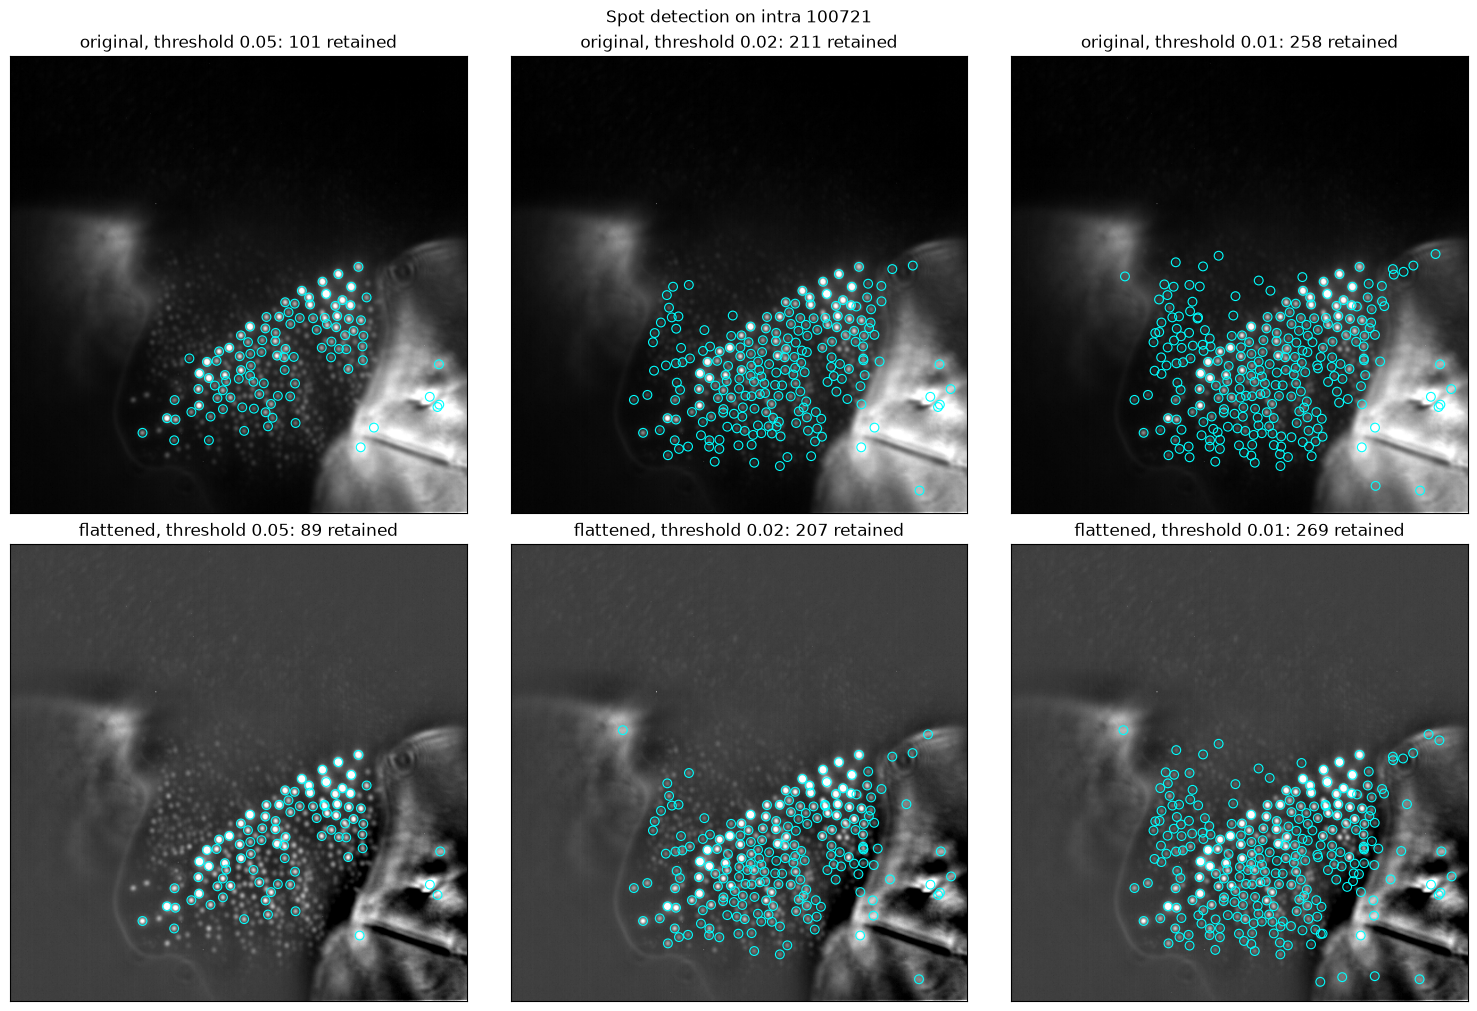

In [22]:
from scipy.ndimage import median_filter, gaussian_filter


def remove_broad_background(img, median_size=41, smooth_sigma=20):
    """Estimate the slowly varying background (as in Week 5) and subtract it."""
    broad = gaussian_filter(median_filter(img, size=median_size), smooth_sigma)
    return img - broad, broad


test_name = list(intras)[0]          # tune on the first intra only
raw_img = mean_imgs[test_name]
flat_img, broad_img = remove_broad_background(raw_img)

thresholds = [0.05, 0.02, 0.01]      # 0.05 is the paper's default
versions = {"original": raw_img, "flattened": flat_img}

detections = {}
print(f"{'image':>10} {'threshold':>10} {'detected':>9} {'retained':>9} {'median R':>9}")
for label, img in versions.items():
    for th in thresholds:
        fits = fit_candidates(img, AnalysisConfig(blob_threshold=th))
        kept = fits[fits["retained"]]
        detections[(label, th)] = fits
        print(f"{label:>10} {th:>10} {len(fits):>9} {len(kept):>9} {kept['R'].median():>9.2f}")


# ---- Show retained spots on each version ----
fig, axes = plt.subplots(2, 3, figsize=(15, 10), layout="constrained")

for row, (label, img) in enumerate(versions.items()):
    lo, hi = np.percentile(img, [1, 99.5])
    for col, th in enumerate(thresholds):
        ax = axes[row, col]
        fits = detections[(label, th)]
        kept = fits[fits["retained"]]

        ax.imshow(img, cmap="gray", vmin=lo, vmax=hi)
        ax.scatter(kept["x"], kept["y"], s=40, facecolors="none",
                   edgecolors="cyan", linewidths=0.8)
        ax.set_title(f"{label}, threshold {th}: {len(kept)} retained")
        ax.set_xticks([])
        ax.set_yticks([])

fig.suptitle(f"Spot detection on intra {test_name}")
plt.show()

### What this shows

- **Lowering the threshold recovers many missed spots.** At the paper's default
  threshold (0.05), ~100 spots are retained and many dim spots visible in the lower-left
  of the band are missed. At 0.02 the count roughly doubles (~210) and covers almost all
  of the visible band.
- **The extra detections look like real spots.** The median fitted width R stays at
  2.09–2.19 px across all settings, so the additional detections have the same shape as
  the bright spots found at the default threshold, rather than being noise or edges.
- **0.01 is too low.** It adds a further ~50 spots, but more are scattered in faint or
  empty areas and around the bright structures, and a third of its detections are
  rejected by the fit (392 detected, 258 retained) against a quarter at 0.02.
  **I use a threshold of 0.02.**
- **Background flattening makes little difference on this recording** (e.g. 211 vs 207
  retained at 0.02), because the intra background is already fairly even. It was
  introduced for the inters, whose backgrounds are much less uniform (median 135–221 ADU),
  so I keep it and check its effect there.
- **Some detections sit on the edges of the bright non-QD structure** (air pocket / PMMA
  edge) on the right, in every version. Because this structure is identical in every
  intra, these false spots would match perfectly between repeats and inflate the
  reliability of the spatial fingerprint. They need to be excluded before comparing
  recordings.
- Settings were chosen on this single intra only, and are applied unchanged to all
  eight recordings next.

### 4b. Detecting spots in all recordings, excluding non-QD structures

I now apply the settings chosen in 4a (background flattening + `blob_threshold = 0.02`)
unchanged to all eight recordings.

**Masking the bright non-QD structures.** 4a showed false detections along the edges of
the large bright structures (air pockets, PMMA edges). For the PUF comparison this is a
serious problem: these structures appear in the same place in every intra, so their
false "spots" would match perfectly between repeats and inflate the reliability of the
fingerprint. I therefore exclude them using a simple, reproducible rule rather than
drawing regions by hand:
1. A **grey opening** with a 15 × 15 px window (`scipy.ndimage.grey_opening`) removes
   every feature smaller than the window — including the ~10 px QD spots, even where they
   are densely packed, since every window contains dark gaps between spots — while large,
   solid bright structures survive.
   *(A first attempt used the broad background map from the flattening step instead.
   This failed: in densely packed regions the QD spots themselves raise the 41 px median
   filter, so the mask swallowed the densest, brightest QD regions and differed between
   repeats of the same region.)*
2. Any pixel where the opened image is more than **1.3×** its own median is marked as
   structure. Using each recording's own median accounts for the different background
   levels between regions found in chunk 2 (135–221 ADU).
3. The mask is grown by **8 px** in every direction, because the sharp edges are exactly
   where false spots appear, and the smoothing blurs the true edge position.
4. Any retained spot whose centre lies inside the mask is excluded.

The factor 1.3 and the 8 px growth were chosen by eye, so the figure below is a check that
the mask covers the structures without swallowing large areas of genuine QDs.

Detected 100721
Detected 101036
Detected 101425
Detected 101720
Detected 101949
Detected 095458
Detected 102951
Detected 105225

    name   type  retained  masked out  final  median R  mask area %
  100721  intra       207         149     58      2.03         30.7
  101036  intra       206         122     84      1.87         28.8
  101425  intra       194          93    101      1.91         27.1
  101720  intra       197          73    124      1.94         26.0
  101949  intra       184          78    106      1.74         26.7
  095458  inter       171          92     79      1.94         14.2
  102951  inter        29          17     12      3.07         14.5
  105225  inter       169         130     39      2.17         27.8


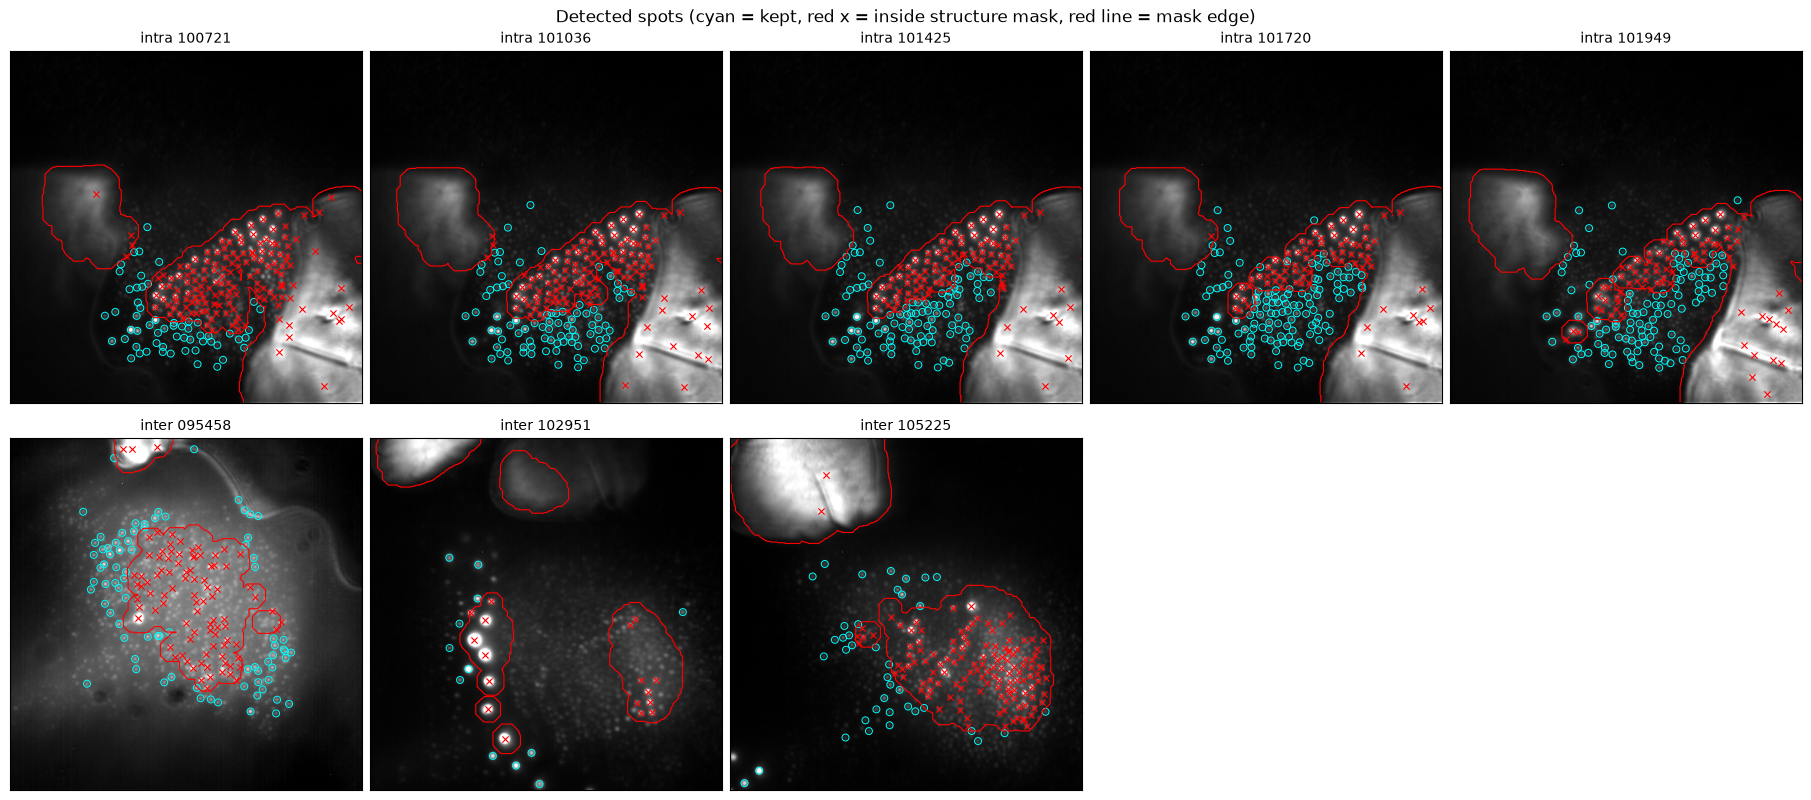

In [25]:
from scipy.ndimage import binary_dilation, grey_opening

DETECT_CFG = AnalysisConfig(blob_threshold=0.02)   # chosen in 4a
MASK_FACTOR = 1.3                                  # opened image > 1.3 x its median -> structure
MASK_GROW = 8                                      # grow the mask by this many pixels
SPOT_REMOVE_SIZE = 15                              # wider than a spot (~10 px across)

def structure_mask(img, factor=MASK_FACTOR, grow=MASK_GROW, size=SPOT_REMOVE_SIZE):
    """True wherever there is a large bright structure.
    Grey opening removes anything smaller than `size` (i.e. the QD spots, even when
    densely packed) but keeps large solid structures, which are then thresholded."""
    opened = grey_opening(img, size=(size, size))
    mask = opened > factor * np.median(opened)
    return binary_dilation(mask, iterations=grow)


def detect_spots(mean_img):
    """Flatten, detect and fit spots, then flag any that fall inside the structure mask."""
    flat, broad = remove_broad_background(mean_img)
    mask = structure_mask(mean_img)

    fits = fit_candidates(flat, DETECT_CFG)
    kept = fits[fits["retained"]].copy()

    # Look up the mask at each spot's (rounded) centre
    xi = np.clip(np.round(kept["x"]).astype(int), 0, mask.shape[1] - 1)
    yi = np.clip(np.round(kept["y"]).astype(int), 0, mask.shape[0] - 1)
    kept["in_mask"] = mask[yi, xi]
    return kept, mask


all_spots, spots, masks = {}, {}, {}
for name, img in mean_imgs.items():
    all_spots[name], masks[name] = detect_spots(img)
    spots[name] = all_spots[name][~all_spots[name]["in_mask"]]   # the spots we keep
    print(f"Detected {name}")


# ---- Summary table ----
print(f"\n{'name':>8} {'type':>6} {'retained':>9} {'masked out':>11} {'final':>6} "
      f"{'median R':>9} {'mask area %':>12}")
for name in mean_imgs:
    kind = "intra" if name in intras else "inter"
    n_all = len(all_spots[name])
    n_final = len(spots[name])
    print(f"{name:>8} {kind:>6} {n_all:>9} {n_all - n_final:>11} {n_final:>6} "
          f"{spots[name]['R'].median():>9.2f} {100 * masks[name].mean():>12.1f}")


# ---- Figure: mask outline, kept spots and excluded spots on each mean image ----
fig, axes = plt.subplots(2, 5, figsize=(18, 8), layout="constrained")

for ax, name in zip(axes[0], intras):
    ax.set_title(f"intra {name}", fontsize=10)
for ax, name in zip(axes[1], inters):
    ax.set_title(f"inter {name}", fontsize=10)

panels = list(zip(axes[0], intras)) + list(zip(axes[1], inters))
for ax, name in panels:
    img = mean_imgs[name]
    lo, hi = np.percentile(img, [1, 99.5])
    ax.imshow(img, cmap="gray", vmin=lo, vmax=hi)

    # Mask outline in red
    ax.contour(masks[name], levels=[0.5], colors="red", linewidths=0.8)

    excluded = all_spots[name][all_spots[name]["in_mask"]]
    ax.scatter(spots[name]["x"], spots[name]["y"], s=25, facecolors="none",
               edgecolors="cyan", linewidths=0.7)
    ax.scatter(excluded["x"], excluded["y"], s=20, marker="x", color="red", linewidths=0.8)

for ax in axes[1, len(inters):]:
    ax.set_visible(False)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle("Detected spots (cyan = kept, red x = inside structure mask, red line = mask edge)")
plt.show()